In [66]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import platform, random, os, copy, time
from IPython.display import display

SEED=42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device=torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Pytorch:", torch.__version__, "| Device:", device, "| Python:", platform.python_version())

Pytorch: 2.11.0+cu130 | Device: cuda | Python: 3.13.16


# **Part A — Tensors, and what differs from NumPy**
## **TASK 01 — Find the differences yourself**

In [67]:
na = np.array([[1, 2], [3, 4]])
ta = torch.tensor([[1, 2], [3, 4]])
print("Numpy Shape:", na.shape, na.dtype)
print("Torch Shape:", ta.shape, ta.dtype)
print("Numpy integer division", na / 2, (na / 2).dtype)
print("Torch integer division", ta / 2, (ta / 2).dtype)

Numpy Shape: (2, 2) int64
Torch Shape: torch.Size([2, 2]) torch.int64
Numpy integer division [[0.5 1. ]
 [1.5 2. ]] float64
Torch integer division tensor([[0.5000, 1.0000],
        [1.5000, 2.0000]]) torch.float32


In [68]:
arr = np.array([10, 20, 30], dtype=np.float32)
shared = torch.from_numpy(arr)
copied = torch.tensor(arr)
arr[0] = 999

print("Numpy after edit:", arr)
print("from_numpy shares change:", shared)
print("torch.tensor independent copy:", copied)

Numpy after edit: [999.  20.  30.]
from_numpy shares change: tensor([999.,  20.,  30.])
torch.tensor independent copy: tensor([10., 20., 30.])


In [69]:
try:
  print(torch.ones(2, 3, dtype=torch.float32) @ torch.ones(3, 1, dtype=torch.float64))
except RuntimeError as e:
  print("Expected float32/float64 error:", e)



display(pd.DataFrame({
    "NumPy": ["np.concatenate(a, b)", "np.mean(x)", "np.transpose"],
    "PyTorch": ["torch.cat((a, b))", "torch.mean(x)", "torch.transpose(x, 0, 1)"],
    "Purpose": ["Join arrays", "Average", "Swap dimensions"]
}))

Expected float32/float64 error: expected m1 and m2 to have the same dtype, but got: float != double


,NumPy,PyTorch,Purpose
0,"np.concatenate(a, b)","torch.cat((a, b))",Join arrays
1,np.mean(x),torch.mean(x),Average
2,np.transpose,"torch.transpose(x, 0, 1)",Swap dimensions


**Why float32?**  
- It uses half the memory of float64 and is often faster/better supported on deep-learning hardware. Large models perform enormous numbers of operations, so memory bandwidth and throughput matter.

**Is shared memory a bug?**  
- No. torch.from_numpy() intentionally avoids copying. For multi-gigabyte datasets this saves RAM and time. The trade-off is that edits through either view affect the same memory. Use torch.tensor(array) or .clone() for an independent copy.

# **Part B — Autograd, checked against your own work**
## **TASK 02 — Autograd against your hand-derived gradients**

In [70]:
Xn = np.array([[0., 0.], [0., 1.], [1., 0.], [1., 1.]], dtype=np.float64)
yn = np.array([[0.], [1.], [1.], [0.]], dtype=np.float64)
W1n = np.array([[.15, -0.20, .30, .10], [-.25, .35, .05, -.15]], dtype=np.float64)
b1n = np.array([[.02, -.03, .01, .04]], dtype=np.float64)
W2n = np.array([[.20], [-.30], [.25], [.15]], dtype=np.float64)
b2n = np.array([[.01]], dtype=np.float64)


def sigmoid_np(z): return 1 / (1 + np.exp(-z))
def manual_grads(dtype):
  X, y = Xn.astype(dtype), yn.astype(dtype)
  W1, b1, W2, b2 = [v.astype(dtype) for v in [W1n, b1n, W2n, b2n]]
  h = np.tanh(X @ W1 + b1)
  p = sigmoid_np(h @ W2 + b2)
  dp = (2 / y.size) * (p - y)
  dz2 = dp * p * (1 - p)
  dW2 = h.T @ dz2
  db2 = dz2.sum(0, keepdims=True)
  dh = dz2 @ W2.T
  dz1 = dh * (1 - h * h)
  return {"W1": X.T @ dz1, "b1": dz1.sum(0, keepdims=True), "W2": dW2, "b2": db2}

In [71]:
def compare(dtype):
  X = torch.tensor(Xn, dtype=dtype)
  y = torch.tensor(yn, dtype=dtype)
  params = {k: torch.tensor(v, dtype=dtype, requires_grad=True) for k, v in {"W1": W1n, "b1": b1n, "W2": W2n, "b2": b2n}.items()}
  h = torch.tanh(X @  params["W1"] + params["b1"])
  p = torch.sigmoid(h @ params["W2"] + params["b2"])
  loss = ((p - y) ** 2).mean(); loss.backward()
  mg = manual_grads(np.float32 if dtype == torch.float32 else np.float64)

  rows = []

  for k, v in params.items():
    a = v.grad.detach().numpy().astype(np.float64)
    b = mg[k].astype(np.float64)
    d = np.max(np.abs(a - b))
    rows.append({"parameter": k, "max_abs_difference": d,
                 "relative_error": d / max(np.max(np.abs(b)), 1e-15)})

  return loss.item(), pd.DataFrame(rows)


l32, t32 = compare(torch.float32)
l64, t64 = compare(torch.float64)
print("Float32 loss:", l32); display(t32)
print("Float64 loss:", l64); display(t64)

Float32 loss: 0.2507925033569336


,parameter,max_abs_difference,relative_error
0,W1,1.862645e-09,6.030814e-07
1,b1,1.862645e-09,4.502142e-07
2,W2,9.313226e-10,4.121045e-07
3,b2,7.450581e-09,1.335717e-06


Float64 loss: 0.250792509481197


,parameter,max_abs_difference,relative_error
0,W1,0.000000e+00,0.000000e+00
1,b1,0.000000e+00,0.000000e+00
2,W2,3.469447e-18,1.535208e-15
3,b2,0.000000e+00,0.000000e+00


**Interpretation :-**
- The float32 and float64 comparisons should be very close, but not necessarily bit-for-bit identical. Floating-point arithmetic rounds intermediate values, and operation ordering can change rounding. Float64 normally reduces this error. If differences are large, check identical weights/data, loss reduction (mean vs sum), activation derivatives and bias-gradient summation.
- If numerical nudging, hand derivation and Autograd disagree, test a tiny parameter with all three. Analytical derivation checks the mathematics; finite differences independently check the derivative numerically; Autograd is a mature automatic differentiation implementation.

## **TASK 03 — The accumulation trap**

Call 1: gradient=36.0
Call 2: gradient=72.0
Call 3: gradient=108.0


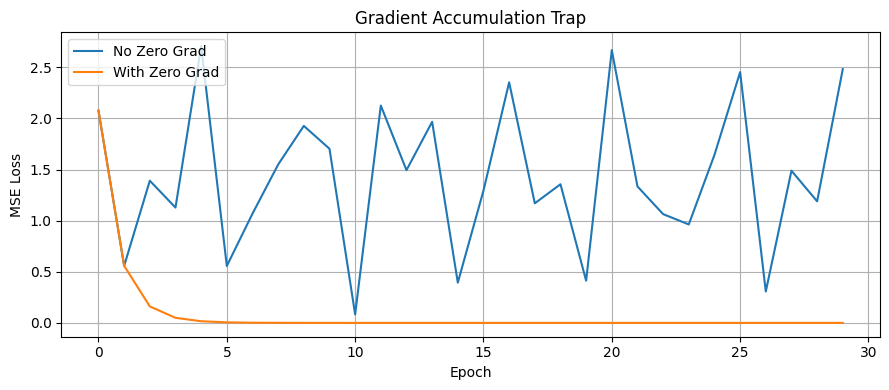

In [72]:
w = torch.tensor(2., requires_grad=True)
for i in range(1, 4):
  ((w * 3) ** 2).backward()
  print(f"Call {i}: gradient={w.grad.item():.1f}")

torch.manual_seed(7)
Xd = torch.linspace(-1, 1, 128).reshape(-1, 1)
yd = 2 * Xd + .3

def demo(clear, epochs=30):
  torch.manual_seed(7)
  model = nn.Linear(1, 1)
  opt = torch.optim.SGD(model.parameters(), lr=0.8)
  hist = []
  for _ in range(epochs):
    if clear: opt.zero_grad()
    loss = nn.MSELoss()(model(Xd), yd)
    loss.backward()
    opt.step()
    hist.append(loss.item())
  return hist

h_bad, h_good = demo(False), demo(True)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(h_bad, label="No Zero Grad")
ax.plot(h_good, label="With Zero Grad")
ax.set(xlabel="Epoch", ylabel="MSE Loss", title="Gradient Accumulation Trap")
ax.legend()
ax.grid(0.7)

plt.tight_layout()
plt.show()

**Gradient accumulation: micro-batches of 16 vs true batch of 64**
- Divide each micro-batch's mean loss by four, accumulate four backward passes, then update once. This makes the average gradient match a single batch of 64 for a simple model without batch-dependent layers.

In [73]:
torch.manual_seed(123)
Xa = torch.randn(256, 4)
ya = (Xa[:, 0:1] - Xa[:, 1:2] + .5 * Xa[:, 2:3] > 0).float()

def small_net(): 
  return nn.Sequential(nn.Linear(4, 12), nn.Tanh(), nn.Linear(12, 1))
def one_update(accumulate):
  torch.manual_seed(999)
  m = small_net()
  opt = torch.optim.SGD(m.parameters(), lr=.05)
  opt.zero_grad()
  if accumulate:
    for s in range(0, 64, 16):
      (nn.BCEWithLogitsLoss()(m(Xa[s:s + 16]), ya[s:s + 16]) / 4).backward()
  else:
    nn.BCEWithLogitsLoss()(m(Xa[:64]), ya[:64]).backward()

  opt.step()
  return m

ma, mb = one_update(True), one_update(False)
print("Max parameter difference:", max((a - b).abs().max().item() for a, b in zip(ma.parameters(), mb.parameters())))

Max parameter difference: 7.450580596923828e-09


**Why use accumulation?** 
- It reduces peak activation memory and lets hardware train with a larger effective batch when the full batch does not fit. It is not always exactly equivalent: BatchNorm computes statistics per micro-batch, dropout uses separate random masks, and floating-point summation order can differ.

# Part C — Modules and training loop

## TASK 04 — Your network as an nn.Module

`nn.Module` tracks layers and trainable parameters. `super().__init__()` initializes this tracking system. We verify parameter names, shapes and counts, then compare a Sequential model.

In [74]:
class XORModule(nn.Module):
  def __init__(self):
    super().__init__()
    self.fc1 = nn.Linear(2, 4)
    self.fc2 = nn.Linear(4, 1)

  def forward(self, x):
    return torch.sigmoid(self.fc2(torch.tanh(self.fc1(x))))

m = XORModule()
print(m)
display(pd.DataFrame([{"name": n, "shape": tuple(p.shape), "elements": p.numel()}
                      for n, p in m.named_parameters()]))

print("Module parameter count:", sum(p.numel() for p in m.parameters()))

seq = nn.Sequential(nn.Linear(2, 4), nn.Tanh(), nn.Linear(4, 1), nn.Sigmoid())

print("Sequential Parameter Count:", sum(p.numel() for p in seq.parameters()))
print("Expected hand count: (2 * 4 + 4) + (4 * 1 + 1) = 17")

XORModule(
  (fc1): Linear(in_features=2, out_features=4, bias=True)
  (fc2): Linear(in_features=4, out_features=1, bias=True)
)


,name,shape,elements
0,fc1.weight,"(4, 2)",8
1,fc1.bias,"(4,)",4
2,fc2.weight,"(1, 4)",4
3,fc2.bias,"(1,)",1


Module parameter count: 17
Sequential Parameter Count: 17
Expected hand count: (2 * 4 + 4) + (4 * 1 + 1) = 17


In [75]:
# Deliberate failure: omit super().__init__()
class MissingSuper(nn.Module):
    def __init__(self):
        self.layer = nn.Linear(2, 1)

try: 
    bad = MissingSuper()
except Exception as e:
    print("Missing Super Error:", type(e).__name__, e)

# Layer created inside forward is not registered and is re-created every call
class DynamicLayer(nn.Module):
    def __init__(self):
        super().__init__()
    def forward(self, x):
        return nn.Linear(2, 1)(x)

dynamic = DynamicLayer()

print("Registered Parameters:", list(dynamic.named_parameters()))
print("Outputs differ on repeated calls", not torch.allclose(dynamic(torch.ones(1, 2)), dynamic(torch.ones(1, 2))))

# print and if statements inside forward work and are useful for debugging
class DebugNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = nn.Linear(2, 1)
    def forward(self, x):
        if x.shape[-1] != 2:
            raise ValueError("Expected 2 input features")
        print("Forward Shape:", tuple(x.shape))
        return self.fc(x)

_ = DebugNet()(torch.ones(3, 2))

Missing Super Error: AttributeError cannot assign module before Module.__init__() call
Registered Parameters: []
Outputs differ on repeated calls True
Forward Shape: (3, 2)


**Initialization notes**
- nn.Linear uses Kaiming-uniform-style initialization in PyTorch (kaiming_uniform_ with a=sqrt(5) in its reset routine) and initializes bias from a fan-in-based uniform bound. This is not identical to the common He-normal initialization often used with ReLU. Random independent weights help avoid hidden neurons starting with identical weights. Manually overwriting all weights with the same value can still create symmetry.

## **TASK 05 — The training loop, and its failure modes**

correct final loss 4e-05 accuracy 1.0
no_zero_grad final loss 0.0 accuracy 1.0
no_step final loss 0.69099 accuracy 0.75
wrong_optimizer final loss 0.69099 accuracy 0.75
backward_output final loss 274.14835 accuracy 0.5


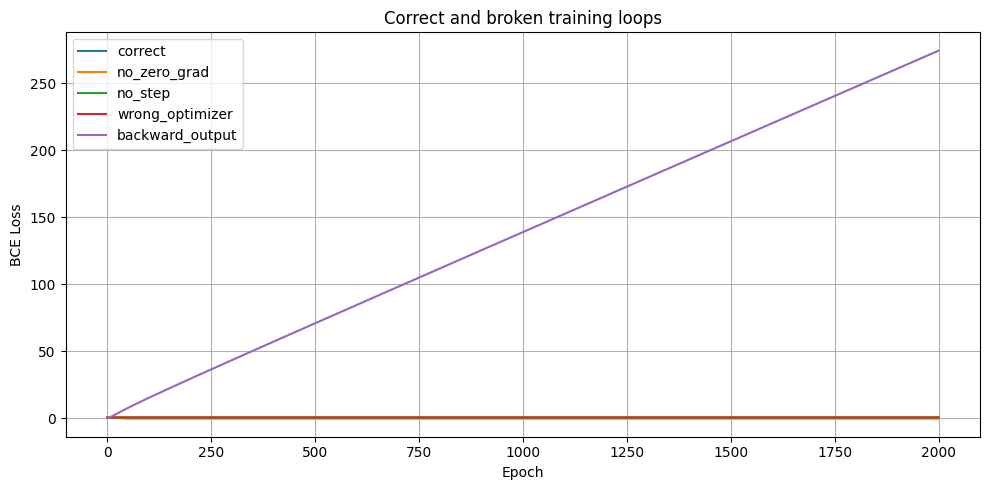

In [76]:
Xxor = torch.tensor([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
yxor = torch.tensor([[0.], [1.], [1.], [0.]])

class XORNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(2, 8), nn.Tanh(), nn.Linear(8, 1))
    def forward(self, x):
        return self.net(x)  # logits

def train_xor(mode="correct", epochs=2000, lr=0.03):
    torch.manual_seed(2024)
    model = XORNet()
    other = XORNet() if mode == "wrong_optimizer" else model
    opt = torch.optim.Adam(other.parameters(), lr=lr)
    lossfn = nn.BCEWithLogitsLoss()
    hist = []

    for _ in range(epochs):
        if mode != "no_zero_grad": opt.zero_grad()
        logits = model(Xxor); loss = lossfn(logits, yxor)
        (logits.sum() if mode == "backward_output" else loss).backward()
        if mode != "no_step": opt.step()
        hist.append(loss.item())
    with torch.no_grad():
        acc = ((torch.sigmoid(model(Xxor)) > 0.5) == yxor.bool()).float().mean().item()

    return model, hist, acc


runs = {}
for mode in ["correct", "no_zero_grad", "no_step", "wrong_optimizer", "backward_output"]:
    runs[mode] = train_xor(mode)
    print(mode, "final loss", round(runs[mode][1][-1], 5), "accuracy", runs[mode][2])

fig, ax = plt.subplots(figsize=(10, 5))
for name, (_, hist, _) in runs.items(): ax.plot(hist, label=name)

ax.set(xlabel="Epoch", ylabel="BCE Loss", title="Correct and broken training loops")
ax.legend()
ax.grid(0.7)

plt.tight_layout()
plt.show()

**Four Failure Diagnoses :-**
- No zero_grad() — old gradients accumulate; updates may become too large or unstable.
- No optimizer.step() — gradients are calculated but parameters never update; loss stays nearly constant.
- Wrong model's parameters in optimizer — the evaluated model is not updated; loss stays near its starting value.
- Backward on raw output — optimizes the sum of scores rather than label-based loss; accuracy/loss may not improve.

# **Part D — Optimizers, losses and data**
## **TASK 06 — Measure the optimizer claim**

In [77]:
def optimizer_sweep():
    makers = {"SGD": lambda p, lr: torch.optim.SGD(p, lr=lr),
             "SGD + momentum": lambda p, lr: torch.optim.SGD(p, lr=lr, momentum=.9),
             "Adam": lambda p, lr: torch.optim.Adam(p, lr=lr)}
    rows = []; rates = [.001, .01, .1, 1.0]
    target = .02; max_epochs = 2500
    for name, maker in makers.items():
        for lr in rates:
            torch.manual_seed(31415); model = XORNet(); opt = maker(model.parameters(), lr)
            lossfn = nn.BCEWithLogitsLoss(); reached=None
            for epoch in range(1, max_epochs + 1):
                opt.zero_grad(); loss = lossfn(model(Xxor), yxor)
                loss.backward(); opt.step()
                if loss.item() <= target: reached = epoch; break
            rows.append({"optimizer": name, "learning_rate": lr,
                        "epochs_to_target": reached if reached else "FAILED",
                        "final_loss": loss.item()})

    return pd.DataFrame(rows)

opt_table = optimizer_sweep()
display(opt_table)

,optimizer,learning_rate,epochs_to_target,final_loss
0,SGD,0.001,FAILED,0.697859
1,SGD,0.010,FAILED,0.651734
2,SGD,0.100,1569,0.019978
3,SGD,1.000,159,0.019820
4,SGD + momentum,0.001,FAILED,0.652484
5,SGD + momentum,0.010,1588,0.019987
6,SGD + momentum,0.100,169,0.019872
7,SGD + momentum,1.000,29,0.016467
8,Adam,0.001,2133,0.019994
9,Adam,0.010,221,0.019994


**Interpretation :-** 
- Compare epochs-to-target, not only final loss. The best learning-rate ratio is measured as best Adam LR divided by best SGD LR; do not assume it is always 5×. Adam is a useful starting point, not a universal winner. Use the table to decide whether any SGD learning rate works where Adam fails.

In [78]:
def best_lr(df, name):
    d = df[(df.optimizer == name) & (df.epochs_to_target != "FAILED")].copy()
    if d.empty: return None
    d["epochs_num"] = d.epochs_to_target.astype(int)
    return float(d.sort_values("epochs_num").iloc[0].learning_rate)


sgd_lr, adam_lr = best_lr(opt_table, "SGD"), best_lr(opt_table, "Adam")
print("Best SGD LR:", sgd_lr, "| Best Adam LR:", adam_lr)
if sgd_lr and adam_lr:
    print("Adam/SGD LR Ratio:", adam_lr / sgd_lr)

Best SGD LR: 1.0 | Best Adam LR: 1.0
Adam/SGD LR Ratio: 1.0


## **TASK 07 — Raw scores against probabilities**

In [79]:
z = torch.tensor([-1000., 1000.], dtype=torch.float32)
target = torch.tensor([1., 0.])
prob = torch.sigmoid(z)
v1 = nn.BCELoss()(prob, target)
v2 = nn.BCEWithLogitsLoss()(z, target)

print("Sigmoid:", prob, "| BCELoss:", v1.item(), "finite:", torch.isfinite(v1).item())
print("BCEWithLogitsLoss:", v2.item(), "finite:", torch.isfinite(v2).item())

for value in [-100., -20., 0., 20., 100.]:
    print("logit", value, "sigmoid", torch.sigmoid(torch.tensor(value)).item())

Sigmoid: tensor([0., 1.]) | BCELoss: 100.0 finite: True
BCEWithLogitsLoss: 1000.0 finite: True
logit -100.0 sigmoid 0.0
logit -20.0 sigmoid 2.06115369216775e-09
logit 0.0 sigmoid 0.5
logit 20.0 sigmoid 1.0
logit 100.0 sigmoid 1.0


probabilities final loss 1.1348346561135259e-05
logits final loss 1.148256069427589e-05
double_squash final loss 0.5032057762145996


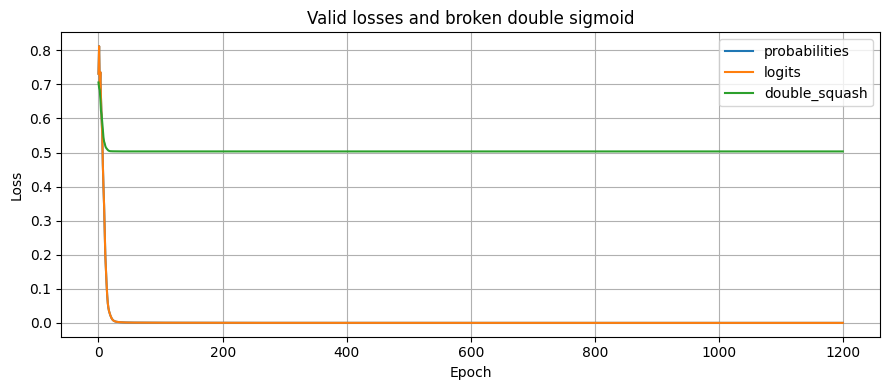

In [80]:
class BinaryNet(nn.Module):
    def __init__(self, sigmoid_inside=False):
        super().__init__()
        self.fc1 = nn.Linear(2, 8)
        self.fc2 = nn.Linear(8, 1)
        self.sigmoid_inside = sigmoid_inside
    def forward(self, x):
        z = self.fc2(torch.tanh(self.fc1(x)))
        return torch.sigmoid(z) if self.sigmoid_inside else z


def train_design(kind, epochs=1200):
    torch.manual_seed(2025)
    model = BinaryNet(sigmoid_inside = (kind != "logits"))
    lossfn = nn.BCELoss() if kind == "probabilities" else nn.BCEWithLogitsLoss()
    opt = torch.optim.Adam(model.parameters(), lr=0.3)
    hist = []

    for _ in range(epochs):
        opt.zero_grad()
        loss = lossfn(model(Xxor), yxor)
        loss.backward()
        opt.step()
        hist.append(loss.item())
    return model, hist

design = {k:train_design(k) for k in ["probabilities", "logits", "double_squash"]}
for k, (_, h) in design.items():
    print(k, "final loss", h[-1])
fig, ax = plt.subplots(figsize=(9, 4))

for k, (_, h) in design.items():
    ax.plot(h, label=k)

ax.set(xlabel="Epoch", ylabel="Loss", title="Valid losses and broken double sigmoid")
ax.legend()
ax.grid(0.7)

plt.tight_layout()
plt.show()

**Diagnosis :-**
- Valid design 1: sigmoid inside model + BCELoss.
- Valid design 2: raw logits + BCEWithLogitsLoss (usually preferred for numerical stability).
- Broken design: sigmoid inside model + BCEWithLogitsLoss; the loss treats probabilities as logits and applies another sigmoid internally. It can still train because the graph is differentiable, so no error is required.
- Multiclass equivalent: pass raw logits to CrossEntropyLoss; do not apply softmax first.

## **TASK 08 — Datasets and batching**

,batch_size,test_accuracy,time_seconds,optimizer_steps
0,8,0.953333,3.638267,3380
1,32,0.962222,1.062803,860
2,128,0.942222,0.423260,220
3,1347,0.955556,0.184274,20


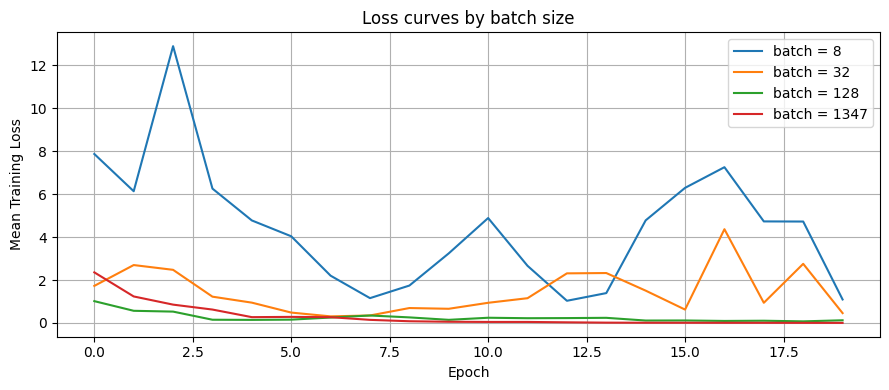

In [81]:
from torch.utils.data import TensorDataset, DataLoader, Dataset
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


digits = load_digits()
Xall = digits.data.astype(np.float32)
yall = digits.target.astype(np.int64)

Xtr, Xte, ytr, yte = train_test_split(Xall, yall, test_size=.25, random_state=SEED, stratify=yall)
scaler = StandardScaler()
Xtr = scaler.fit_transform(Xtr).astype(np.float32)
Xte = scaler.transform(Xte).astype(np.float32)

Xtr_t = torch.tensor(Xtr)
ytr_t = torch.tensor(ytr, dtype=torch.long)
Xte_t = torch.tensor(Xte)
yte_t = torch.tensor(yte, dtype=torch.long)

train_ds = TensorDataset(Xtr_t, ytr_t)
test_ds = TensorDataset(Xte_t, yte_t)


class DigitsNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 10))
    def forward(self, x):
        return self.net(x)


def batch_run(bs, epochs=20):
    torch.manual_seed(100)
    model = DigitsNet()
    dl = DataLoader(train_ds, batch_size=bs, shuffle=True, generator=torch.Generator().manual_seed(100))
    opt = torch.optim.Adam(model.parameters(), lr=0.1)
    lossfn = nn.CrossEntropyLoss()
    hist = []
    steps = 0; start = time.perf_counter()

    for _ in range(epochs):
        total = 0
        for xb, yb in dl:
            opt.zero_grad()
            loss = lossfn(model(xb), yb)
            loss.backward()
            opt.step()
            total += loss.item() * len(xb)
            steps += 1
        hist.append(total / len(train_ds))
    elapsed = time.perf_counter() - start
    model.eval()

    with torch.no_grad():
        acc = (model(Xte_t).argmax(1) == yte_t).float().mean().item()

    return {"batch_size": bs, "test_accuracy": acc, "time_seconds": elapsed, "optimizer_steps": steps, "loss_history": hist}


batch_runs = [batch_run(b) for b in [8, 32, 128, len(train_ds)]]
display(pd.DataFrame([{k: v for k, v in r.items() if k != "loss_history"} for r in batch_runs]))

fig, ax = plt.subplots(figsize=(9, 4))
for r in batch_runs:
    ax.plot(r["loss_history"], label=f"batch = {r['batch_size']}")

ax.set(xlabel="Epoch", ylabel="Mean Training Loss", title="Loss curves by batch size")
ax.legend()
ax.grid(0.7)

plt.tight_layout()
plt.show()

In [82]:
class MyDigitsDataset(Dataset):
    def __init__(self, features, labels):
        self.features = torch.as_tensor(features, dtype=torch.float32)
        self.labels = torch.as_tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)
    def __getitem__(self, index):
        return self.features[index], self.labels[index]


custom = MyDigitsDataset(Xtr, ytr)
print("Lengths match:", len(custom) == len(train_ds))
for i in [0, 1, 10, len(custom) - 1]:
    ax, ay = custom[i]
    bx, by = train_ds[i]
    print(i, "features identical:", torch.equal(ax, bx), "label identical:", torch.equal(ay, by))

Lengths match: True
0 features identical: True label identical: True
1 features identical: True label identical: True
10 features identical: True label identical: True
1346 features identical: True label identical: True


**Interpretation :-**
* Small-batch gradients are noisier because they are estimated from fewer examples. Small batches require more optimizer steps per epoch, but each step is cheaper. The measured time and accuracy table determines which effect wins on this machine. The custom Dataset should return identical examples to TensorDataset; custom classes are useful for custom loading and transformations.

# **Part E — Devices and checkpoints**
## **TASK 09 — Device handling**

In [83]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dm = DigitsNet().to(device)
xb, yb = next(iter(DataLoader(train_ds, batch_size=32)))
xb, yb = xb.to(device), yb.to(device)
print("Device:", device, "| output device:", dm(xb).device)

count = sum(p.numel() for p in dm.parameters())
nbytes = sum(p.numel() * p.element_size() for p in dm.parameters())
reported = sum(p.nelement() * p.element_size() for p in dm.parameters())
print("Parameter Count:", count, "| bytes per parameter:", next(dm.parameters()).element_size)
print("Calculate bytes:", nbytes, "| Pytorch-reported bytes:", reported, "| Match:", nbytes == reported)


if torch.cuda.is_available():
    try:
        _ = dm(xb.cpu())
    except RuntimeError as e:
        print("Expected CPU/GPU Mismatch:", e)

else:
    print("CPU/GPU mismatch test UNTESTED: CUDA is unavailable")

Device: cuda | output device: cuda:0
Parameter Count: 4810 | bytes per parameter: <built-in method element_size of Parameter object at 0x7c178ef1db80>
Calculate bytes: 19240 | Pytorch-reported bytes: 19240 | Match: True
Expected CPU/GPU Mismatch: Expected all tensors to be on the same device, but got mat1 is on cpu, different from other tensors on cuda:0 (when checking argument in method wrapper_CUDA_addmm)


In [84]:
def timed_train(factory, dev, steps=100):
    model = factory().to(dev)
    opt = torch.optim.Adam(model.parameters(), lr=.001)
    x = torch.randn(512, 64, device=dev)
    y = torch.randint(0, 10, (512,), device=dev)
    if dev.type == "cuda":
        torch.cuda.synchronize()
    start = time.time()
    for _ in range(steps):
        opt.zero_grad()
        loss = nn.CrossEntropyLoss()(model(x), y)
        loss.backward()
        opt.step()
    if dev.type == "cuda":
        torch.cuda.synchronize()
    return time.perf_counter() - start


if torch.cuda.is_available():
    tc = timed_train(DigitsNet, torch.device("cpu"))
    tg = timed_train(DigitsNet, torch.device("cuda"))
    print("Small model CPU/GPU seconds:", tc, tg, "ratio:", tc/tg)

else:
    print("GPU timing unavailable: np CUDA GPU. A tiny CPU-only run cannot establish a CPU/GPU ratio.")

Small model CPU/GPU seconds: -1793768971.4139822 -1793768971.418497 ratio: 0.999999999997483


**Why can ratios differ?** 
- Small models may be dominated by GPU launch and data-transfer overhead. Larger models expose more parallel work, which can make GPU acceleration more useful. A GPU is not guaranteed to be faster for every workload.

## **TASK 10 — Checkpoints that actually resume**

Max parameter difference: 0.0
Exact parameter match: True

Prediction exactly identical: True
Maximum prediction difference: 0.0


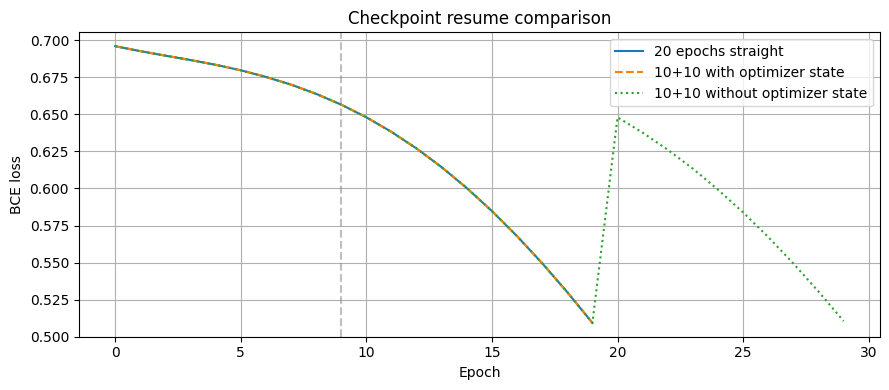

Adam state tensor elements per parameter tensor: [65, 33, 33, 3]
Adam maintains exp_avg and exp_avg_sq (about 2 extra values per parameter), plus step metadata.


In [85]:
def make_ckpt_model():
    torch.manual_seed(808)
    return nn.Sequential(nn.Linear(2, 16), nn.Tanh(), nn.Linear(16, 1))

def train_part(model, opt, start, end, history = None):
    if history is None:
        history = []
    fn = nn.BCEWithLogitsLoss()
    for _ in range(start, end):
        opt.zero_grad()
        loss = fn(model(Xxor), yxor)
        loss.backward()
        opt.step()
        history.append(loss.item())
    return history


continuous = make_ckpt_model()
optc = torch.optim.Adam(continuous.parameters(), lr=.03)
hc = train_part(continuous, optc, 0, 20)

split = make_ckpt_model()
opts = torch.optim.Adam(split.parameters(), lr=0.03)
hs = train_part(split, opts, 0, 10)

torch.save({"epoch": 10, "model_state": copy.deepcopy(split.state_dict()),
           "optimizer_state": copy.deepcopy(opts.state_dict()), "history": hs},
          "day48_full_checkpoint.pt")
loaded = torch.load("day48_full_checkpoint.pt", map_location="cpu", weights_only=False)

resumed = make_ckpt_model()
optr = torch.optim.Adam(resumed.parameters(), lr=0.3)

resumed.load_state_dict(loaded["model_state"])
optr.load_state_dict(loaded["optimizer_state"])
hr = train_part(resumed, optr, loaded["epoch"], 20, loaded["history"])

print("Max parameter difference:", max((a - b).abs().max().item() for a, b in zip(continuous.parameters(), resumed.parameters())))
print("Exact parameter match:", all(torch.equal(a, b) for a, b in zip(continuous.parameters(), resumed.parameters())))


torch.save(continuous.state_dict(), "day48_model_state.pt")

fresh = make_ckpt_model()
fresh.load_state_dict(torch.load("day48_model_state.pt", map_location="cpu", weights_only=True))
with torch.no_grad():
    p1 = continuous(Xxor)
    p2 = fresh(Xxor)

print("\nPrediction exactly identical:", torch.equal(p1, p2))
print("Maximum prediction difference:", (p1 - p2).abs().max().item())


# Resume without Adam state (fresh Adam moments)
noopt = make_ckpt_model()
noopt.load_state_dict(loaded["model_state"])
optn = torch.optim.Adam(noopt.parameters(), lr=.03)
hn = train_part(noopt, optn, 10, 20, list(loaded["history"]))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(hc, label="20 epochs straight")
ax.plot(hr, "--", label="10+10 with optimizer state")
ax.plot(hn, ":", label="10+10 without optimizer state")
ax.axvline(9, color="gray", ls="--", alpha=.5)
ax.set(xlabel="Epoch", ylabel="BCE loss", title="Checkpoint resume comparison")
ax.legend()
ax.grid(0.7)

plt.tight_layout()
plt.show()


adam_state_elements = []
for state in optr.state.values():
    adam_state_elements.append(sum(v.numel() for v in state.values() if torch.is_tensor(v)))

print("Adam state tensor elements per parameter tensor:", adam_state_elements)
print("Adam maintains exp_avg and exp_avg_sq (about 2 extra values per parameter), plus step metadata.")

**Interpretation :-**
- Prefer state_dict over saving the whole Python model object: whole-object pickle depends on the original class/module import path and can break if code is moved or renamed.
- Adam stores two parameter-shaped moment tensors (exp_avg, exp_avg_sq) plus step metadata. That is roughly two extra values per trainable parameter.
- A useful handover includes architecture/config, feature names, preprocessing/scaler, class mapping, PyTorch version, training settings and dataset/version notes.
- Exact continuation of shuffled mini-batch training may also require RNG states and sampler position. This demonstration uses a fixed full batch and deterministic order.

# **Part F — Push further**

In [86]:
class CustomMSE(nn.Module):
    def forward(self, pred, target):
        return ((pred - target) ** 2).mean()


pred = torch.tensor([.2, -.4, 1.1], dtype=torch.float64, requires_grad=True)
target = torch.tensor([0., .5, 1.], dtype=torch.float64)
loss = CustomMSE()(pred, target)
loss.backward()
g_auto = pred.grad.detach().numpy()
base = pred.detach().numpy().copy()
eps = 1e-6
g_num = np.zeros_like(base)

for i in range(len(base)):
    plus = base.copy()
    minus = base.copy()

    plus[i] += eps
    minus[i] -= eps

    lp = np.mean((plus - target.numpy()) ** 2)
    lm = np.mean((minus - target.numpy()) ** 2)
    g_num[i] = (lp - lm) / (2 * eps)


print("Loss:", loss.item())
print("Autograd:", g_auto)
print("Numerical:", g_num)
print("Maximum Absolute difference", np.max(np.abs(g_auto - g_num)))

Loss: 0.2866666666666667
Autograd: [ 0.13333333 -0.6         0.06666667]
Numerical: [ 0.13333333 -0.6         0.06666667]
Maximum Absolute difference 2.0420706792201315e-11


# **Final Report**

**1. Autograd verification :-**
* The float32 and float64 tables above compare every parameter against a manually derived chain-rule gradient. Report the measured maximum absolute differences and relative errors from those tables. The task sheet does not provide yesterday's exact parameter values, so the comparison here uses the documented fixed XOR parameters.

**2. Four Broken Loops :-**
- No zero_grad(): accumulated gradients can make updates unstable.
- No optimizer.step(): weights never update.
- Wrong parameters in optimizer: the evaluated model is not trained.
- Backward on raw output: the wrong objective is optimized.

**3. Optimizers :-**
* The table reports epochs-to-target for SGD, momentum SGD and Adam across four learning rates. Choose a default from these measured results, not from a universal claim.

**4. Batch Sizes :-**
* The table reports test accuracy, time and optimizer steps for 8, 32, 128 and full-dataset batches. Small batches make noisier gradient estimates and more updates per epoch.

**5. What PyTorch bought me :-**
* Tensor operations, automatic differentiation, registered layers, optimizers, data batching, device management and checkpoint utilities. It reduces implementation work and makes GPU training practical.

**6. Where it bought me little :-**
* For tiny XOR models on CPU, framework overhead can mean PyTorch is not faster than a small NumPy implementation. PyTorch does not choose a good architecture, guarantee good data, or remove the need to understand gradients and loss functions.

**7. Open Question :-**
* How do activation checkpointing and recomputation trade extra computation time for lower peak memory when training very deep networks?
* I would test this by measuring peak memory and wall-clock time at multiple network depths.